# Pipeline Creation using MotherSettings

In this example, we demonstrate how to use the MotherSettings file to generate a pipeline using defaults. To simplify this step an example config file is provided by the mother package. However, own files can be loaded in the same way.
First, all steps are performed individually to exemplify what happens in each step. Second, it is shown how a complete training pipeline with defaults is created in 5 lines of code.

In [1]:
import logging
import pickle
import typing
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn.metrics as skl_metrics
import sklearn.model_selection as skl_model_sel
from matplotlib import pyplot as plt
from optuna.trial import Trial
from rdkit.Chem import Draw, PandasTools
from sklearn import pipeline as sklearn_pipeline
from sklearn.pipeline import FeatureUnion, Pipeline

import mother.ml as ml
import mother.optimization as opt
from mother import feature_generation as fg
from mother import pipeline_utils as mother_takes_care
from mother.cv import report as cv_report
from mother.ml.core import AbstractMotherPipeline
from mother.settings import MotherSettings

PandasTools.RenderImagesInAllDataFrames(True)
logging.basicConfig(level=logging.INFO)
project_dir: Path = Path.cwd().parent  # Points to examples/notebooks/ directory
project_dir

PosixPath('/home/sagemaker-user/MotherML/examples/notebooks')

### Load default settings file from mother package

In [2]:
mother_settings: MotherSettings = MotherSettings.create()
mother_settings.model.categorical_features = []  # remove categorical features
mother_settings

{
    "input": {
        "file": "examples/notebooks/freesolv_train.csv",
        "separator": ",",
        "structure_col": "smiles",
        "target_columns": [
            "expt"
        ],
        "group_col": "cat_col"
    },
    "pipeline": {
        "memory": null,
        "verbose": false,
        "transform": "pandas",
        "n_jobs": null,
        "remainder": "passthrough",
        "verbose_feature_names_out": false
    },
    "preprocessing": {
        "flags": [
            "STANDARDIZE",
            "NEUTRALIZE",
            "DESALT"
        ]
    },
    "feature_generation": {
        "fingerprints": [
            {
                "MorganFP": {
                    "radius": 2,
                    "fpSize": 1024,
                    "includeChirality": false
                }
            }
        ],
        "maccs": true,
        "chemical_descriptors": {
            "omit_prefixes": [
                "fr_",
                "FpDensity"
            ],
            "desc

If you want to dump the config you can use the following function. Afterwards you can edit the file and reload it again

In [3]:
mother_settings.dump_to_yaml(project_dir.joinpath("my_mother_settings.yaml"))

### Load input data from input file

In [4]:
input_file: Path = Path("../freesolv_train.csv")
data: pd.DataFrame = pd.read_csv(input_file, sep=",")
data = data.loc[:100, ["iupac", "smiles", "expt"]]
data.head()

,iupac,smiles,expt
0,"4-methoxy-N,N-dimethyl-benzamide",CN(C)C(=O)c1ccc(cc1)OC,-11.01
1,methanesulfonyl chloride,CS(=O)(=O)Cl,-4.87
2,3-methylbut-1-ene,CC(C)C=C,1.83
3,2-ethylpyrazine,CCc1cnccn1,-5.45
4,heptan-1-ol,CCCCCCCO,-4.21


The compound preprocessing has to be performed in advance to create the required groups for the CV and FeatureSelector

In [5]:
# preprocessing
preprocessor: sklearn_pipeline.Pipeline = mother_takes_care.get_preprocessing_pipeline(settings=mother_settings)
preprocessor.set_output(transform=mother_settings.pipeline.transform)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('smiles_standardizer', ...), ('smiles_to_mol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,flags,"['STANDARDIZE', 'NEUTRALIZE', ...]"
,smiles_col,None
,error,'ignore'
,smiles_col,None
,molecule_col,'Molecule'


In [6]:
structure_data: pd.Series = data[mother_settings.input.structure_col]
mol_data: pd.DataFrame = preprocessor.fit_transform(structure_data)  # type: ignore
preprocessor

INFO:mother.preprocessing.core:Standardizing SMILES with flags: ['STANDARDIZE', 'NEUTRALIZE', 'DESALT']
[18:12:41] Initializing Normalizer
[18:12:41] Initializing MetalDisconnector
[18:12:41] Initializing Normalizer


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('smiles_standardizer', ...), ('smiles_to_mol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,flags,"['STANDARDIZE', 'NEUTRALIZE', ...]"
,smiles_col,None
,error,'ignore'
Name,Type,Value
n_features_in_,int,1


In [7]:
mol_data.columns

Index(['Molecule'], dtype='object')

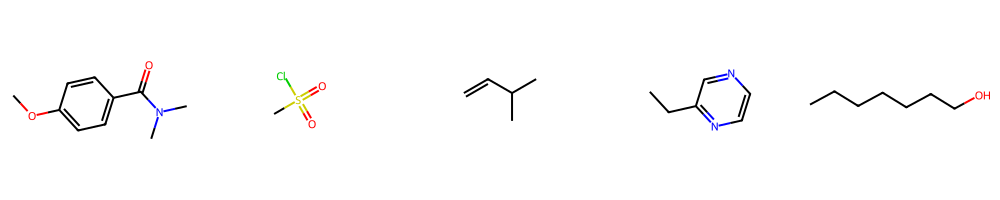

In [8]:
molecule_col: str = "Molecule"
Draw.MolsToGridImage(mol_data[molecule_col].head(), molsPerRow=5, subImgSize=(200, 200))

## Get CV data and folds

In the following the groups are gemerated using the mother convenience functions. This function creates the required transformer and returns the groups as a result

INFO:mother.feature_generation.fp_gen:Creating fingerprint generator 'MorganFP'
INFO:mother.cv.cv_methods:Applying clustering with Tanimoto similarity: 0.4
INFO:mother.cv.cv_methods:Found: 42 clusters


array([[<Axes: title={'center': 'tanimoto-group'}>]], dtype=object)

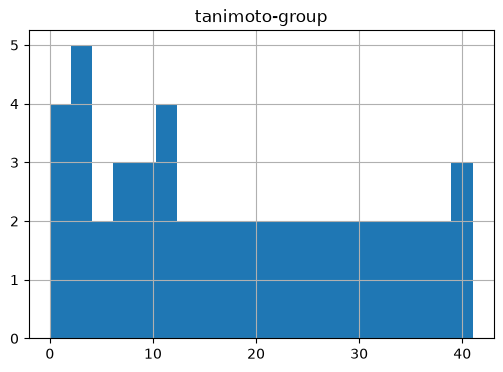

In [9]:
groups: typing.Optional[pd.DataFrame] = mother_takes_care.get_groups(
    settings=mother_settings, mol_data=mol_data[molecule_col]
)
assert groups is not None
groups.hist(xlabelsize=10, ylabelsize=10, bins=20, figsize=(6, 4))

Now generate the CV folds for the training/validation. Here, since we are training a regression model, you get a GroupKFold cross-validator.
If you want to train a classification model, you automatically get a StratifiedGroupKFold cross-validator.

In [10]:
cv: skl_model_sel.BaseCrossValidator = mother_takes_care.get_cv_folds(settings=mother_settings, group_data=groups)
cv

INFO:mother.pipeline_utils:Creating GroupKFold cross-validator using 5 splits


GroupKFold(n_splits=5, random_state=None, shuffle=False)

<Axes: title={'center': 'GroupKFold  (42 groups; each group entirely in train or test)'}, xlabel='Sample index (sorted by group)', ylabel='CV iteration'>

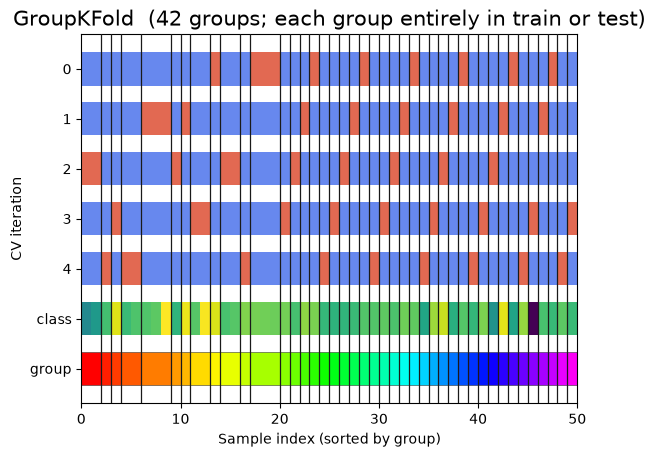

In [11]:
cv_report.plot_cv_indices(
    cv=cv,
    X=np.array(mol_data),
    y=data["expt"],
    group=groups.iloc[:, 0].values,  # Extract the first (and likely only) column of group data as array
    ax=plt.gca(),
    n_splits=mother_settings.cv.n_splits,
)

### Next step would be the feature generation.

In [12]:
feature_data: Path = project_dir.joinpath(Path(mother_settings.input.file).stem + "_features.csv")

feature_generator: FeatureUnion = mother_takes_care.get_feature_generation_pipeline(settings=mother_settings)
feature_generator.set_output(transform=mother_settings.pipeline.transform)
feature_matrix: pd.DataFrame = feature_generator.fit_transform(mol_data[molecule_col])
# ensure valid dtypes for feature selection
feature_matrix = feature_matrix.convert_dtypes()
feature_matrix.shape

INFO:mother.pipeline_utils:Creating feature generation pipeline
INFO:mother.pipeline_utils:Feature generation pipeline created
INFO:mother.feature_generation.core:Calculating MACCS fingerprints
INFO:mother.feature_generation.core:Calculating MorganFP fingerprints using parameters: {'fpSize': 1024, 'countSimulation': False, 'countBounds': None, 'atomInvariantsGenerator': None, 'radius': 2, 'includeChirality': False, 'useBondTypes': True, 'includeRedundantEnvironments': False, 'includeRingMembership': True, 'onlyNonzeroInvariants': False}
INFO:mother.feature_generation.fp_gen:Creating fingerprint generator 'MorganFP'


(50, 1320)

Visualize Feature Union

In [13]:
feature_matrix.head()

,Maccs__maccs_0,Maccs__maccs_1,Maccs__maccs_2,Maccs__maccs_3,Maccs__maccs_4,Maccs__maccs_5,Maccs__maccs_6,Maccs__maccs_7,Maccs__maccs_8,Maccs__maccs_9,...,MorganFP__MorganFP_1014,MorganFP__MorganFP_1015,MorganFP__MorganFP_1016,MorganFP__MorganFP_1017,MorganFP__MorganFP_1018,MorganFP__MorganFP_1019,MorganFP__MorganFP_1020,MorganFP__MorganFP_1021,MorganFP__MorganFP_1022,MorganFP__MorganFP_1023
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
feature_generator

,transformer_list,"[('Maccs', ...), ('Desc', ...), ...]"
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,omit_prefixes,"('fr_', ...)"
,descriptor_prefix,'rdkit_'
,descriptor_list,"['MaxAbsEStateIndex', 'MaxEStateIndex', ...]"
,fp_type,'MorganFP'
,parameters,"{'atomInvariantsGenerator': None, 'countBounds': None, 'countSimulation': False, 'fpSize': 1024, ...}"
,use_counts,True


### Feature Selection

Use default feature selection provided by mother. Catboost model used in feature selector is silenced via mother settings. just as an example, the default loss function is replaced.

In [15]:
mother_settings.model.parameters["loss_function"] = "Quantile"
mother_settings.model.parameters["silent"] = True
mother_settings.model.feature_selection_type = "catboost"
mother_settings.model.correlation_threshold = 0.95  # drop highly correlated features
mother_settings.model.feature_selection_threshold = 0.1  # drop unimportant features
mother_settings.model.feature_selection_flags = [
    "DROP_CONSTANT",
    "DROP_CORRELATED",
    "DROP_DUPLICATES",
    "DROP_UNIMPORTANT",
]
feature_selector = mother_takes_care.get_feature_selection_pipeline(
    settings=mother_settings,
    cv=None,  # use internal CV since CV with groups is not supported
)
feature_selector.set_output(transform=mother_settings.pipeline.transform)
feature_matrix_sel: pd.DataFrame = feature_selector.fit_transform(
    feature_matrix, data[mother_settings.input.target_columns]
)
feature_matrix_sel.shape

INFO:mother.pipeline_utils:Creating feature selection pipeline for numeric columns.
INFO:mother.pipeline_utils:The default correlation method is used
INFO:mother.pipeline_utils:Boruta usage: False
INFO:mother.ml:Loaded 14 model classes: NODEClassifier, NODERegressor, LassoClassifierMother, LassoRegressorMother, TabICLClassifierMother, TabICLRegressorMother, RandomForestClassifierMother, RandomForestRegressorMother, TabPFNClassifierMother, TabPFNRegressorMother, CatboostClassifierMother, CatboostGaussianProcessRegressorMother, CatboostRankerMother, CatboostRegressorMother
INFO:mother.ml.utils:Using 'RMSE' as loss function.
INFO:mother.pipeline_utils:Setting up catboost importance feature selection
INFO:mother.ml.estimators:Finished catboost feature importance calculation
INFO:mother.ml.estimators:Feature importances have been turned into percentiles
INFO:mother.ml.estimators:Initialized catboost feature importance estimator


(50, 207)

#### Visualization of the Feature Selector

Since there is no categorical column in the input, the CategoricalImputer is not used. The used feature selectors are part of a pipeline that runs consecutively on all input columns.

In [16]:
mother_takes_care.report_feature_selection(feature_selector, data=feature_matrix)

INFO:mother.pipeline_utils:Analyzing feature selection pipeline
INFO:mother.pipeline_utils:Analyzing feature_selector transformer
INFO:mother.pipeline_utils:Nested pipeline found
INFO:mother.pipeline_utils:Pipeline step: duplicate_selector
INFO:mother.pipeline_utils:Features to drop: {'MorganFP__MorganFP_82', 'MorganFP__MorganFP_776', 'MorganFP__MorganFP_42', 'MorganFP__MorganFP_384', 'MorganFP__MorganFP_554', 'MorganFP__MorganFP_863', 'Maccs__maccs_5', 'MorganFP__MorganFP_385', 'MorganFP__MorganFP_995', 'MorganFP__MorganFP_172', 'MorganFP__MorganFP_823', 'MorganFP__MorganFP_402', 'MorganFP__MorganFP_900', 'MorganFP__MorganFP_937', 'MorganFP__MorganFP_966', 'MorganFP__MorganFP_675', 'MorganFP__MorganFP_45', 'MorganFP__MorganFP_415', 'MorganFP__MorganFP_571', 'MorganFP__MorganFP_572', 'MorganFP__MorganFP_1000', 'MorganFP__MorganFP_917', 'MorganFP__MorganFP_758', 'MorganFP__MorganFP_211', 'MorganFP__MorganFP_88', 'MorganFP__MorganFP_610', 'Maccs__maccs_23', 'MorganFP__MorganFP_341', 'Mor

In [17]:
feature_selector

,transformers,"[('feature_selector', ...)]"
,remainder,'passthrough'
,verbose_feature_names_out,False
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
Name,Type,Value
feature_names_in_,"ndarray[object](1320,)","['Maccs__maccs_0','Maccs__maccs_1','Maccs__maccs_2',..., 'MorganFP__MorganFP_1021','MorganFP__MorganFP_1022', 'MorganFP__MorganFP_1023']"
n_features_in_,int,1320
named_transformers_,Bunch,{'feature_sel...shold=0.1))])}


# Creating a training pipeline from a settings object

Here you can see how a complete training pipeline can be generated using the convenience functions from mother and the required settings.

The steps to be performed are:

1. Preprocess the input data
    1. Standardize SMILES
    2. Convert SMILES to rdkit molecule
2. Create input features from the molecules
    1. Calculate morgan fingerprint
    2. Calculate MACSS keys
    3. Calculate rdkit physchem descriptors
3. Run feature selector
4. Train the model

In [18]:
# silence catboost learning output
mother_settings.model.parameters["silent"] = True
model_steps: typing.Sequence[
    typing.Tuple[str, typing.Union[Pipeline, FeatureUnion, ml.AbstractMotherPipeline, typing.Any]]
] = []
model_steps.append(
    (
        "preprocessor",
        mother_takes_care.get_preprocessing_pipeline(settings=mother_settings),
    )
)
model_steps.append(
    (
        "feature_generator",
        mother_takes_care.get_feature_generation_pipeline(settings=mother_settings),
    )
)
model_steps.append(
    (
        "feature_selector",
        mother_takes_care.get_feature_selection_pipeline(settings=mother_settings),
    )
)
model_steps.append(("model", mother_takes_care.get_model(settings=mother_settings)))
training_pipeline: Pipeline = Pipeline(
    steps=model_steps,
    memory=mother_settings.pipeline.memory,
    verbose=mother_settings.pipeline.verbose,
)
training_pipeline.set_output(transform=mother_settings.pipeline.transform)

INFO:mother.pipeline_utils:Creating feature generation pipeline
INFO:mother.pipeline_utils:Feature generation pipeline created
INFO:mother.pipeline_utils:Creating feature selection pipeline for numeric columns.
INFO:mother.pipeline_utils:The default correlation method is used
INFO:mother.pipeline_utils:Boruta usage: False
INFO:mother.ml.utils:Using 'RMSE' as loss function.
INFO:mother.pipeline_utils:Setting up catboost importance feature selection


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('feature_generator', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('smiles_standardizer', ...), ('smiles_to_mol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,flags,"['STANDARDIZE', 'NEUTRALIZE', ...]"
,smiles_col,None
,error,'ignore'


In the following the model is fit on the training data. The final pipeline is again visualized. You should see a blue coloring of the invidual transformers that indicates that the individual steps are fitted and ready to be used for inference.

In [19]:
training_pipeline.fit(
    data[mother_settings.input.structure_col],
    data[mother_settings.input.target_columns],
)

INFO:mother.preprocessing.core:Standardizing SMILES with flags: ['STANDARDIZE', 'NEUTRALIZE', 'DESALT']
[18:12:49] Initializing Normalizer
[18:12:49] Initializing MetalDisconnector
[18:12:49] Initializing Normalizer
INFO:mother.feature_generation.core:Calculating MACCS fingerprints
INFO:mother.feature_generation.core:Calculating MorganFP fingerprints using parameters: {'fpSize': 1024, 'countSimulation': False, 'countBounds': None, 'atomInvariantsGenerator': None, 'radius': 2, 'includeChirality': False, 'useBondTypes': True, 'includeRedundantEnvironments': False, 'includeRingMembership': True, 'onlyNonzeroInvariants': False}
INFO:mother.feature_generation.fp_gen:Creating fingerprint generator 'MorganFP'
INFO:mother.ml.estimators:Finished catboost feature importance calculation
INFO:mother.ml.estimators:Feature importances have been turned into percentiles
INFO:mother.ml.estimators:Initialized catboost feature importance estimator


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('feature_generator', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](0,)",[]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('smiles_standardizer', ...), ('smiles_to_mol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable cachin

## Inference

Create predictions on SMILES. Since the first step of the pipeline takes SMILES as input, those are used for inference as well. If the preprocessing and feature generation steps would be removed, the input would be a feature matrix with all required columns. The result of the predict function is a numpy array. Since all necessary preprocessing steps are part of the pipeline. The pipeline can be pickled and used on a different machine (having the same python environment and dependencies installed) to do inference.

In [20]:
pickle.dump(training_pipeline, open("/tmp/pipeline.pkl.gz", "wb"))

In [21]:
training_pipeline: Pipeline = pickle.load(open("/tmp/pipeline.pkl.gz", "rb"))
predictions = training_pipeline.predict(data[mother_settings.input.structure_col])
predictions

INFO:mother.preprocessing.core:Standardizing SMILES with flags: ['STANDARDIZE', 'NEUTRALIZE', 'DESALT']
[18:12:58] Initializing Normalizer
[18:12:58] Initializing MetalDisconnector
[18:12:58] Initializing Normalizer
INFO:mother.feature_generation.core:Calculating MACCS fingerprints
INFO:mother.feature_generation.core:Calculating MorganFP fingerprints using parameters: {'fpSize': 1024, 'countSimulation': False, 'countBounds': None, 'atomInvariantsGenerator': None, 'radius': 2, 'includeChirality': False, 'useBondTypes': True, 'includeRedundantEnvironments': False, 'includeRingMembership': True, 'onlyNonzeroInvariants': False}
INFO:mother.feature_generation.fp_gen:Creating fingerprint generator 'MorganFP'


array([-11.01000034,  -4.87000055,   1.83000008,  -5.44999906,
        -4.20999966,  -6.27000058,   2.33999552,  -3.91999982,
         1.57999908,  -4.61999983,  -1.96000046,  -3.87999958,
        -4.32999908,  -2.49000017,  -2.54999964,  -4.78000003,
        -1.46000016,  -2.22000116,  -5.84999973,   2.87999984,
        -6.33999973,  -6.10000038,  -5.47999949,  -4.10000008,
        -4.1000003 ,  -3.5199991 ,  -4.47000062,  -2.74000051,
        -3.43000022,  -7.80999924,  -0.80000097,   0.92996609,
        -6.78000085,  -9.2900002 ,  -4.0700004 ,  -5.90999929,
        -2.13000055,  -3.64000567,  -2.67999997,   3.12999911,
       -10.00000033,   2.06000053,  -8.10999911,  -1.1200007 ,
       -23.62000129,  -2.82999949,  -4.68007386,  -5.56000009,
        -3.65000019,  -5.48999986])

## Example how to access individual parts of the pipeline

You can access each pipeline step by using the name given when the training pipeline was created.

Here, using *model* returns us the catboost object and catboost functions can be used. Here, the feature importance from the model is extracted and visualized.

In [22]:
mother_takes_care.get_feature_importance(pipeline=training_pipeline, model_step_name="model", lowest_importance=1)

,Feature Id,Importances
0,Desc__rdkit_PEOE_VSA1,"13,178"
1,Desc__rdkit_TPSA,"6,412"
2,Desc__rdkit_PEOE_VSA9,"4,016"
3,MorganFP__MorganFP_33,"3,909"
4,Desc__rdkit_Kappa1,"2,954"
5,Desc__rdkit_NumHAcceptors,"2,764"
6,Desc__rdkit_PEOE_VSA8,"2,677"
7,Desc__rdkit_VSA_EState8,"2,621"
8,Desc__rdkit_MolLogP,"2,615"
9,Desc__rdkit_SlogP_VSA5,"2,556"


## Model Tuning using Custom Preprocessing
In the following section the Tuner is used for preprocessing as well.

First, create TunableTransformer for feature generations steps. To be sure that all required methods are implemented, please inherit from 'AbstractMotherPipeline'.

In [23]:
class TunableFeatureGenerationPipeline(fg.MorganFingerprints, AbstractMotherPipeline):
    def transform(self, X, **kwargs):
        return super().transform(X, **kwargs)

    def get_hyperparameter_space(self, X, y, trial: Trial, prefix: str = "") -> dict:
        return {
            prefix + "radius": trial.suggest_int(prefix + "radius", low=1, high=3, step=1),
            prefix + "fpSize": trial.suggest_int(
                prefix + "fpSize",
                low=512,
                step=256,
                high=2048,
            ),
        }

    def default_parameters(self, prefix=""):
        return {
            prefix + "radius": 2,
            prefix + "fpSize": 666,
        }

In [24]:
assert mother_settings.tuning is not None

model_steps: typing.List[typing.Union[Pipeline, FeatureUnion, ml.AbstractMotherPipeline, typing.Any]] = []

model_steps.append(
    (
        "preprocessor",
        mother_takes_care.get_preprocessing_pipeline(settings=mother_settings),
    )
)
model_steps.append(("feature_generator", TunableFeatureGenerationPipeline()))  # custom feature generation for tuning
model_steps.append(
    (
        "feature_selector",
        mother_takes_care.get_feature_selection_pipeline(settings=mother_settings),
    )
)
model_steps.append(("model", mother_takes_care.get_model(settings=mother_settings)))
tuning_pipeline: ml.PipelineWithHyperparameterRooting = ml.PipelineWithHyperparameterRooting(steps=model_steps)
tuning_pipeline.set_output(transform="pandas")
tuning_pipeline

INFO:mother.pipeline_utils:Creating feature selection pipeline for numeric columns.
INFO:mother.pipeline_utils:The default correlation method is used
INFO:mother.pipeline_utils:Boruta usage: False
INFO:mother.ml.utils:Using 'RMSE' as loss function.
INFO:mother.pipeline_utils:Setting up catboost importance feature selection


,steps,"[('preprocessor', ...), ('feature_generator', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('smiles_standardizer', ...), ('smiles_to_mol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,flags,"['STANDARDIZE', 'NEUTRALIZE', ...]"
,smiles_col,None
,error,'ignore'


In [25]:
data.head()

,iupac,smiles,expt
0,"4-methoxy-N,N-dimethyl-benzamide",CN(C)C(=O)c1ccc(cc1)OC,-11.01
1,methanesulfonyl chloride,CS(=O)(=O)Cl,-4.87
2,3-methylbut-1-ene,CC(C)C=C,1.83
3,2-ethylpyrazine,CCc1cnccn1,-5.45
4,heptan-1-ol,CCCCCCCO,-4.21


In [26]:
scorer = skl_metrics.make_scorer(score_func=skl_metrics.root_mean_squared_error, greater_is_better=False)

In [27]:
tuning_pipeline

,steps,"[('preprocessor', ...), ('feature_generator', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('smiles_standardizer', ...), ('smiles_to_mol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,flags,"['STANDARDIZE', 'NEUTRALIZE', ...]"
,smiles_col,None
,error,'ignore'


To see why you need a PipelineWithHyperparameterRooting class and what it is doing for you, have a look at the default_parameters of your pipeline.

In [28]:
tuning_pipeline.default_parameters()

{'feature_generator__radius': 2,
 'feature_generator__fpSize': 666,
 'feature_selector__feature_selector__importance_selector__threshold': np.float64(2.2250738585072014e-308),
 'model__learning_rate': 0.03,
 'model__bootstrap_type': 'MVS',
 'model__random_strength': 1,
 'model__grow_policy': 'SymmetricTree',
 'model__boosting_type': 'Plain',
 'model__max_depth': 6,
 'model__loss_function': 'RMSE'}

In [29]:
tuner = opt.MotherTuner(**mother_settings.tuning.model_dump())
tuner.scorer = scorer
tuner = opt.MotherTuner(
    n_threads_optuna=5,
    scorer=scorer,
    n_trials_optuna=1,
    n_startup_trials=1,
    tuning_direction="maximize",
)
# tune the pipeline
model_tuned = tuner.optimize(
    estimator=tuning_pipeline,
    X=data[[mother_settings.input.structure_col]],
    y=data[mother_settings.input.target_columns],
    cross_validation=cv,
    groups=groups.iloc[:, 0],
)

model_tuned

src/mother/optimization/core.py:170: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  self.sampler = optuna.samplers.TPESampler(
src/mother/optimization/core.py:170: ExperimentalWarning: Argument ``group`` is an experimental feature. The interface can change in the future.
  self.sampler = optuna.samplers.TPESampler(
src/mother/optimization/core.py:170: ExperimentalWarning: Argument ``constant_liar`` is an experimental feature. The interface can change in the future.
  self.sampler = optuna.samplers.TPESampler(
INFO:mother.optimization.core:Setting up Optuna to optimize hyperparameters with direction: maximize
INFO:optuna.storages._in_memory:A new study created in memory with name: no-name-d63bfe10-b49d-4d0f-9d4e-0ecb913b7127
INFO:mother.optimization.core:Running hyperparameter optimization with 1 trials
/tmp/ipykernel_4593/4248749013.py:8: UserWarning: Fixed parameter feature_generator__fpSize with value 666 is out of

{'feature_generator__radius': 2, 'feature_generator__fpSize': 666, 'feature_selector__feature_selector__importance_selector__threshold': 2.2250738585072014e-308, 'model__bootstrap_type': 'MVS', 'model__learning_rate': 0.03, 'model__random_strength': 1.0, 'model__grow_policy': 'SymmetricTree', 'model__max_depth': 6}


INFO:mother.ml.estimators:Finished catboost feature importance calculation
INFO:mother.ml.estimators:Feature importances have been turned into percentiles
INFO:mother.ml.estimators:Initialized catboost feature importance estimator
INFO:mother.optimization.core:Training completed


,steps,"[('preprocessor', ...), ('feature_generator', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[object](0,)",[]
n_features_in_,int,1
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('smiles_standardizer', ...), ('smiles_to_mol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
